# What Works for Whom: Assessing Heterogeneous Treatment Effects

***Hands-on coding notebook -- Segments 3-5***

**Author:** DSxHE Tutorial, Carly Brantner


# Welcome!

This notebook is the hands-on portion of the tutorial and covers **Segments
3 through 5** of today's session:

- **Segment 3** -- reading in the data and looking for early visual clues
  of treatment effect heterogeneity.
- **Segment 4** -- two "traditional" ways to estimate heterogeneous
  treatment effects: a regression interaction term, and a stratified
  (subgroup) analysis.
- **Segment 5** -- a more flexible, modern approach: the causal forest
  (from the `grf` package).

You do not need much of a coding background to follow along -- every chunk
is commented to explain **what** the code does and **why**. Run the chunks
in order, top to bottom (in RStudio: click the little green "Play" arrow at
the top-right of a chunk, or put your cursor in a chunk and press
Cmd/Ctrl + Shift + Enter).

A few pieces near the end of Segment 5 are marked **STRETCH MATERIAL** --
these are optional, "if we have time" pieces you're welcome to run along
with everyone else, or come back to later on your own. A couple of other
spots are marked **"Your turn"** -- short chunks where you pick which
covariate to explore, rather than following along with ours.

> **A note on the data.** Everything in this notebook uses a single
> **simulated** clinical trial dataset created for this tutorial. We picked two real antidepressant
> names (vortioxetine as the "treatment" arm, duloxetine as the "control"
> arm) to make the example feel realistic. **The results below are
> entirely made up and say nothing about the real-world effectiveness of
> either drug** -- please don't cite them as evidence of anything beyond
> "here's how these methods behave on a dataset with known, built-in
> heterogeneity."

**What we're working towards:** We are going to estimate how treatment effects vary across candidate effect moderators. Ultimate visualizations will include things like subgroup-specific treatment effects and conditional average treatment effect (CATE) estimates per characteristic.

---

# Segment 3: Data setup and descriptives

**Goal:** make sure everyone can read in the data, get oriented, and start
looking for visual hints of *who* seems to respond differently to
treatment.

## 3.0 Load the dataset


In [ ]:
data_url <- "https://raw.githubusercontent.com/Data-Science-for-Health-Equity/hte-tutorial/main/data/simulated_mdd_trial.csv"
dat <- read.csv(data_url)

head(dat)

,patient_id,treatment,age,sex,smoker,weight_kg,madrs_baseline,madrs_followup,true_cate
,<int>,<chr>,<int>,<chr>,<chr>,<dbl>,<int>,<int>,<dbl>
1,1,Vortioxetine,66,Female,No,64.6,30,2,2.50
2,2,Vortioxetine,59,Female,No,86.3,25,11,1.06
3,3,Vortioxetine,62,Female,Yes,70.9,29,15,2.07
4,4,Duloxetine,42,Male,No,88.6,31,16,1.05
5,5,Vortioxetine,61,Female,No,89.0,29,13,1.93
6,6,Vortioxetine,42,Male,Yes,104.6,20,11,-1.26


## 3.1 Load the packages we'll need

In [ ]:
# This may take a few minutes...

install.packages(c(
  "tidyverse",
  "grf",
  "rpart",
  "rpart.plot",
  "knitr",
  "table1",
  "gtsummary"
))

# tidyverse = a bundle of packages for data wrangling (dplyr) and plotting
#             (ggplot2) that we'll use throughout
# grf       = "generalized random forests" -- this gives us the causal
#             forest we'll fit in Segment 5
# rpart / rpart.plot = used in Segment 5 to draw a simple "interpretation
#             tree" that summarizes what the causal forest learned
# knitr     = lets us print tidy-looking tables with kable()
# table1    = automatically builds a "Table 1" of baseline characteristics
# gtsummary = builds publication-style summary tables

library(tidyverse)
library(grf)
library(rpart)
library(rpart.plot)
library(knitr)
library(table1)



Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘V8’, ‘litedown’, ‘reactR’, ‘zoo’, ‘bigD’, ‘bitops’, ‘juicyjuice’, ‘markdown’, ‘reactable’, ‘DiceKriging’, ‘lmtest’, ‘sandwich’, ‘RcppEigen’, ‘Formula’, ‘cards’, ‘cardx’, ‘gt’


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘table1’


The following objects are masked from ‘package:base’:

    units, units<-





## 3.2 Understand the data

Each row is one patient enrolled in the trial.



In [ ]:

# Two small housekeeping steps:
# (1) make "treatment" a factor with Duloxetine as the reference/control
#     group, so that regression coefficients for "treatment" describe the
#     effect of being assigned to Vortioxetine
# (2) drop the "true_cate" column from view for now -- in a real dataset
#     you would NEVER get to see the true individual treatment effect!
#     We kept it in the .csv only so we can peek at it for fun at the very
#     end of the notebook.
dat <- dat %>%
  mutate(treatment = factor(treatment, levels = c("Duloxetine", "Vortioxetine")))

dim(dat)       # how many patients (rows) and variables (columns)?
str(dat)       # what type is each variable?
head(dat)      # first few rows


[1] 1000    9

'data.frame':	1000 obs. of  9 variables:
 $ patient_id    : int  1 2 3 4 5 6 7 8 9 10 ...
 $ treatment     : Factor w/ 2 levels "Duloxetine","Vortioxetine": 2 2 2 1 2 2 2 1 1 1 ...
 $ age           : int  66 59 62 42 61 42 56 48 39 53 ...
 $ sex           : chr  "Female" "Female" "Female" "Male" ...
 $ smoker        : chr  "No" "No" "Yes" "No" ...
 $ weight_kg     : num  64.6 86.3 70.9 88.6 89 ...
 $ madrs_baseline: int  30 25 29 31 29 20 28 25 31 32 ...
 $ madrs_followup: int  2 11 15 16 13 11 8 16 10 24 ...
 $ true_cate     : num  2.5 1.06 2.07 1.05 1.93 -1.26 1.35 0.26 0.78 1.97 ...


,patient_id,treatment,age,sex,smoker,weight_kg,madrs_baseline,madrs_followup,true_cate
,<int>,<fct>,<int>,<chr>,<chr>,<dbl>,<int>,<int>,<dbl>
1,1,Vortioxetine,66,Female,No,64.6,30,2,2.50
2,2,Vortioxetine,59,Female,No,86.3,25,11,1.06
3,3,Vortioxetine,62,Female,Yes,70.9,29,15,2.07
4,4,Duloxetine,42,Male,No,88.6,31,16,1.05
5,5,Vortioxetine,61,Female,No,89.0,29,13,1.93
6,6,Vortioxetine,42,Male,Yes,104.6,20,11,-1.26



**Variables in this dataset:**

- `patient_id` -- unique patient identifier
- `treatment` -- randomized arm: Vortioxetine vs. Duloxetine (control)
- `age` -- age in years at enrollment
- `sex` -- Female / Male
- `smoker` -- current smoker at enrollment (Yes/No)
- `weight_kg` -- body weight in kg at enrollment
- `madrs_baseline` -- baseline depression severity (MADRS total score;
  higher = more severe depression)
- `madrs_followup` -- **our outcome**: MADRS total score at the end of the
  study (follow-up), on the same 0-60 scale as `madrs_baseline`. *Lower =
  healthier* -- same direction as baseline severity.
- `true_cate` -- the ground-truth simulated treatment effect for each
  patient (only exists because this is simulated data -- ignore it until
  the very end!)

## 3.3 Understanding the outcome and the treatment effect

Before we compare treatment arms, let's get oriented on the outcome itself.

### 3.3.1 Distribution of the outcome

Our outcome is the **MADRS score at follow-up** (end of study) -- the same
0-60 scale, and the same direction (lower = healthier), as the baseline
score you'll see in Table 1 below. Let's look at where patients started
and where they ended up:



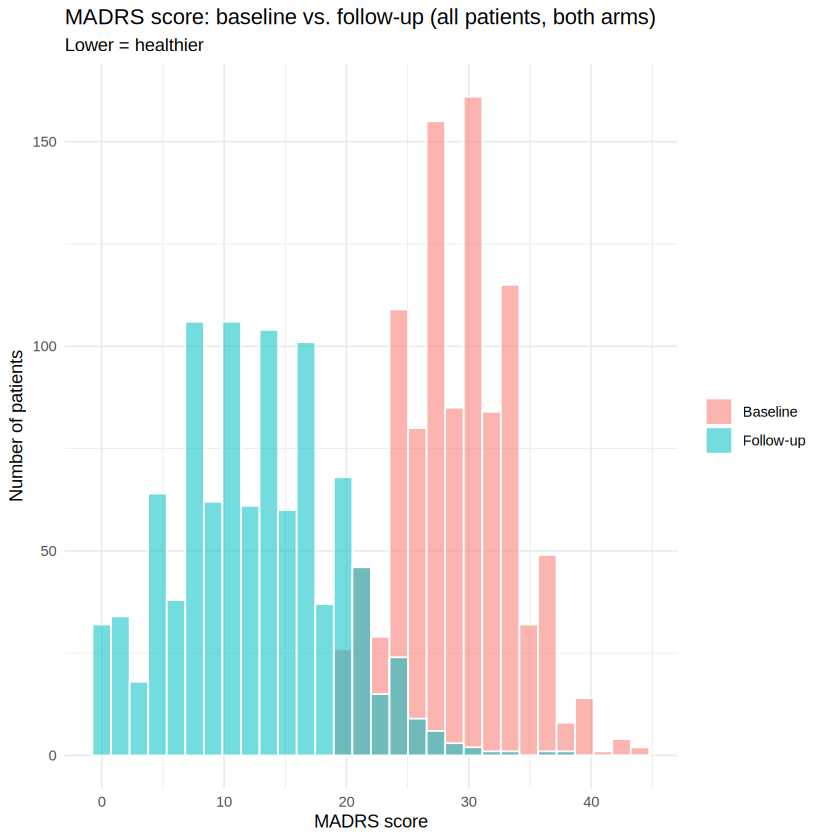

In [ ]:
dat_long <- dat %>%
  select(patient_id, madrs_baseline, madrs_followup) %>%
  pivot_longer(cols = c(madrs_baseline, madrs_followup),
               names_to = "timepoint", values_to = "score") %>%
  mutate(timepoint = recode(timepoint,
                             madrs_baseline = "Baseline",
                             madrs_followup = "Follow-up"),
         timepoint = factor(timepoint, levels = c("Baseline", "Follow-up")))

ggplot(dat_long, aes(x = score, fill = timepoint)) +
  geom_histogram(position = "identity", bins = 30, alpha = 0.55, color = "white") +
  labs(title = "MADRS score: baseline vs. follow-up (all patients, both arms)",
       subtitle = "Lower = healthier",
       x = "MADRS score", y = "Number of patients", fill = NULL) +
  theme_minimal()



As a group, patients clearly shift toward lower (healthier) scores by the
end of the study -- but there's a lot of patient-to-patient spread at
follow-up too, and a few patients end up worse than they started. That's
normal and expected in a real trial, and it's exactly the kind of variation
a treatment-effect analysis is trying to explain.

> **A note on why we're using the follow-up score, not "change from
> baseline."** Many real depression trials use *change from baseline*
> (or an ANCOVA-adjusted follow-up score) as the primary outcome instead
> of the raw follow-up score, since baseline severity is such a strong
> predictor of where a patient ends up. We chose to keep things simple
> here and work directly with the follow-up score, on its native,
> already-familiar MADRS scale (lower = healthier, exactly like the
> baseline score) -- one fewer derived-variable sign convention to keep
> track of. We still get most of the benefit of adjusting for baseline,
> since `madrs_baseline` appears as a covariate in every model in
> Segments 4-5. If you want the extra practice, try redoing this notebook
> with `madrs_followup - madrs_baseline` as your outcome instead and see
> whether your conclusions change.

### 3.3.2 Clinical benchmarks for the MADRS

A few reference points that clinicians use to interpret MADRS scores and
changes (useful for judging whether a treatment-effect estimate is not
just statistically significant, but clinically meaningful):

- **Severity** (applies to *either* timepoint -- baseline or follow-up)
  is commonly classified as: 0-6 no/minimal symptoms, 7-19 mild
  depression, 20-34 moderate depression, 35-60 severe depression. Our
  simulated trial enrolled patients with moderate-to-severe depression at
  baseline (see Table 1 below); you can use this same ruler to judge how
  patients look at follow-up too.
- **Response** to treatment is commonly defined as a $\geq$ 50% reduction
  in MADRS score from baseline (i.e., a follow-up score no higher than
  half of baseline).
- **Remission** is commonly defined as a follow-up MADRS score $\leq$ 10.
- **Minimal clinically important difference (MCID)**: published estimates
  for how large a *between-group* treatment-effect difference needs to be
  to matter to patients range from about 3 to 9 points, with much of the
  literature converging on roughly 3-6 points as the best estimate.
  (Estimates vary by method -- see Hengartner & Plöderl (2022) for an
  anchor- and distribution-based comparison.) This is a useful ruler for
  later: a treatment-effect estimate smaller than ~3-6 points may not be
  meaningful to patients even if it's statistically significant. Note this
  MCID applies to *group-level treatment-effect estimates* (like an ATE or
  CATE), not to any single patient's raw follow-up score above, which will
  naturally vary a lot for reasons unrelated to treatment (baseline
  severity, measurement error, day-to-day fluctuation).

### 3.3.3 What exactly is "the treatment effect"?

Recall from Segment 2: for each patient, imagine two **potential
outcomes** -- $Y(1)$ is the follow-up MADRS score they *would* have if
given vortioxetine, and $Y(0)$ is the follow-up MADRS score they *would*
have if given duloxetine. In real life we only ever observe one of these
per patient (whichever arm they were actually randomized to); the other
is a "what if" we can never directly see.

- **Average Treatment Effect:** $\text{ATE} = E[Y(1) - Y(0)]$, averaged
  over everyone in the trial.
- **Conditional Average Treatment Effect:** $\text{CATE}(x) = E[Y(1) -
  Y(0) \mid X = x]$, the average treatment effect *within* the subgroup of
  patients who share covariate value(s) $x$ (e.g., patients around age
  60). This is what the rest of this notebook is trying to estimate.

**Direction:** since MADRS is a symptom-severity scale (lower = healthier),
a **negative** treatment effect ($Y(1) - Y(0) < 0$) means vortioxetine
achieved a **lower, healthier** follow-up score than duloxetine -- i.e.,
vortioxetine worked better for that patient/subgroup. A **positive**
treatment effect means duloxetine achieved the lower/healthier score --
i.e., duloxetine worked better.

## 3.4 Describe the sample ("Table 1")

Before we compare treatment arms, a reminder that this is a **randomized controlled trial**. `treatment` was assigned
to each patient randomly. In other words, we have **no confounding**, meaning we don't have to worry about patient characteristics that influence *both* who got which drug *and* their ultimate depression severity, so a comparison between arms is already a valid estimate of the causal treatment
effect.

One consequence of randomization: we should expect baseline
characteristics, including baseline severity, to be **balanced** across
arms. Let's check, using the kind of table that appears as "Table 1" in
almost every trial publication.



In [ ]:

tbl1 <- table1(
  ~ age + sex + smoker + weight_kg + madrs_baseline | treatment,
  data = dat,
  overall = "Overall",
  caption = "Table 1. Baseline characteristics by treatment arm."
)

IRdisplay::display_html(as.character(tbl1))


,Duloxetine(N=493),Vortioxetine(N=507),Overall(N=1000)
age,,,
Mean (SD),45.7 (12.6),44.1 (12.1),44.9 (12.4)
"Median [Min, Max]","46.0 [19.0, 75.0]","43.0 [19.0, 75.0]","45.0 [19.0, 75.0]"
sex,,,
Female,375 (76.1%),394 (77.7%),769 (76.9%)
Male,118 (23.9%),113 (22.3%),231 (23.1%)
smoker,,,
No,413 (83.8%),396 (78.1%),809 (80.9%)
Yes,80 (16.2%),111 (21.9%),191 (19.1%)
weight_kg,,,



The two arms should look quite similar, including on baseline
MADRS severity. That's randomization doing its job!

## 3.5 Outcome by treatment group

Let's start simple: does the overall (average) outcome differ by
treatment arm? This unadjusted comparison relates to the ATE we defined above (although we are not directly estimating it at the moment).



treatment,mean_followup,n
<fct>,<dbl>,<int>
Duloxetine,12.21095,493
Vortioxetine,12.58974,507


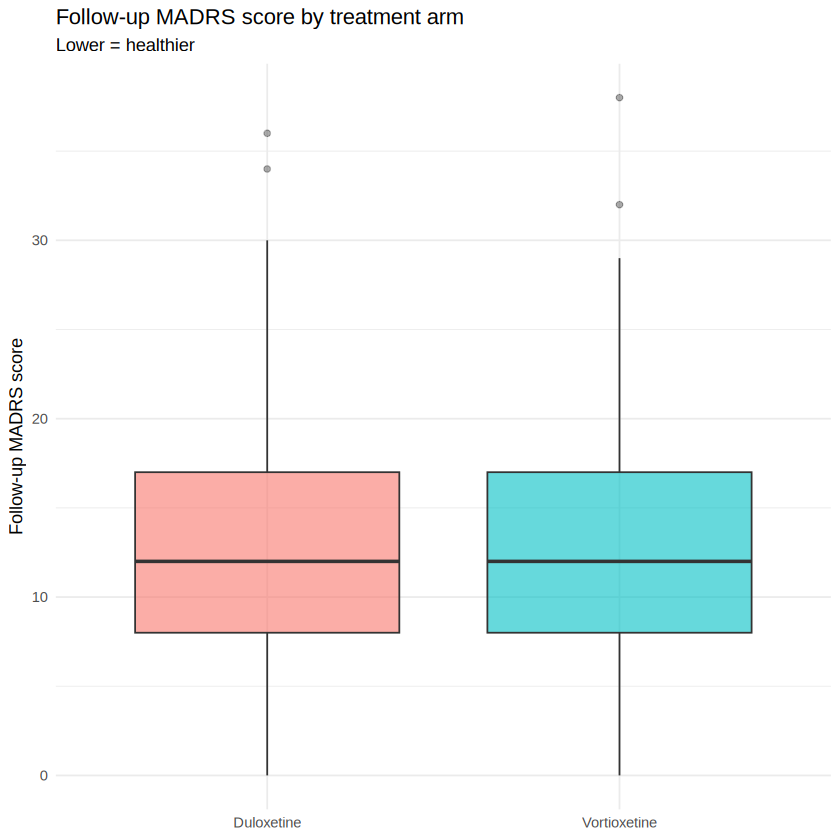

In [ ]:
ggplot(dat, aes(x = treatment, y = madrs_followup, fill = treatment)) +
  geom_boxplot(alpha = 0.6, outlier.alpha = 0.4) +
  labs(title = "Follow-up MADRS score by treatment arm",
       subtitle = "Lower = healthier",
       x = NULL, y = "Follow-up MADRS score") +
  theme_minimal() +
  theme(legend.position = "none")

# The simple average difference between arms -- this is the (unadjusted)
# Average Treatment Effect, or ATE. Remember: lower score is better, so a
# lower mean for one arm means that arm did better.
dat %>%
  group_by(treatment) %>%
  summarise(mean_followup = mean(madrs_followup), n = n())



We can also connect this back to the clinical benchmarks from 3.3.2 --
what fraction of patients in each arm met "response" ($\geq$ 50% reduction
from baseline) or "remission" (follow-up score $\leq$ 10) criteria?



In [ ]:
dat <- dat %>%
  mutate(responder = madrs_followup <= 0.5 * madrs_baseline,  # score dropped by >= 50%
         remission = madrs_followup <= 10)

dat %>%
  group_by(treatment) %>%
  summarise(pct_response = sprintf("%.0f%%", 100 * mean(responder)),
            pct_remission = sprintf("%.0f%%", 100 * mean(remission)),
            .groups = "drop") %>%
  kable(caption = "Response and remission rates by treatment arm")




Table: Response and remission rates by treatment arm

|treatment    |pct_response |pct_remission |
|:------------|:------------|:-------------|
|Duloxetine   |66%          |41%           |
|Vortioxetine |65%          |39%           |


There's not much of a difference on average -- but remember from Segment 2, an *average*
treatment effect can hide the fact that the effect might be very different
for different kinds of patients. Let's go looking for that.

## 3.6 Looking for effect moderators visually

An **effect moderator** is a covariate that changes the *size* of the
treatment effect. One quick, low-tech way to spot a candidate moderator:
plot the outcome against a covariate, colored by treatment arm, and add a
smoothed trend line for each arm. If the two trend lines are roughly
**parallel**, that covariate probably isn't much of a moderator. If the
lines **diverge or cross**, that's a hint of heterogeneity.



`geom_smooth()` using formula = 'y ~ x'


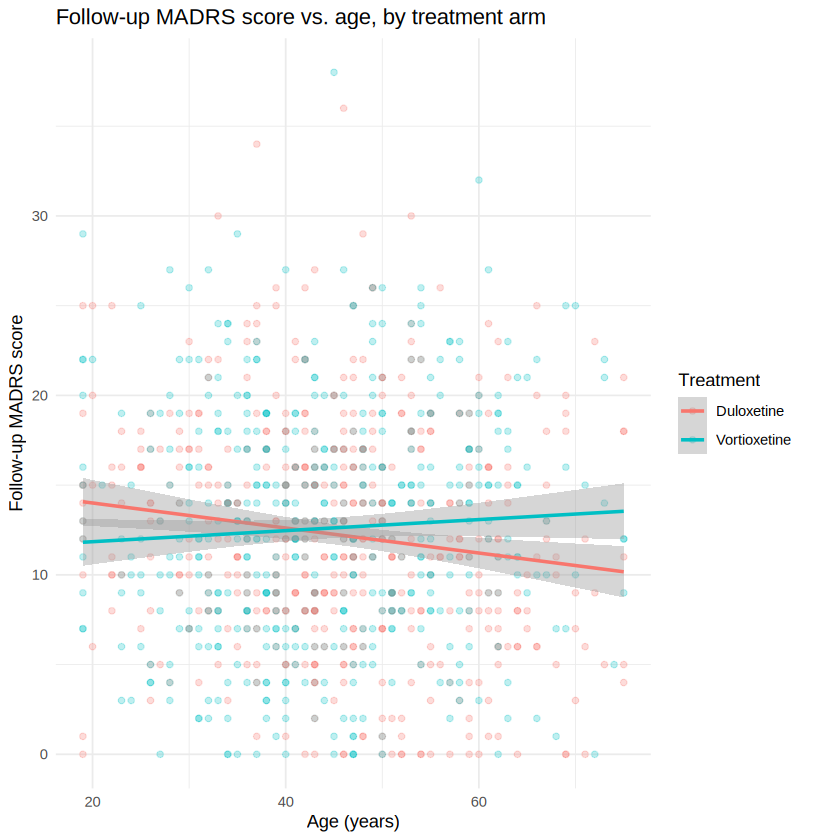

In [ ]:
ggplot(dat, aes(x = age, y = madrs_followup, color = treatment)) +
  geom_point(alpha = 0.25) +
  geom_smooth(method = "lm", se = TRUE) +
  labs(title = "Follow-up MADRS score vs. age, by treatment arm",
       x = "Age (years)", y = "Follow-up MADRS score", color = "Treatment") +
  theme_minimal()


`geom_smooth()` using formula = 'y ~ x'


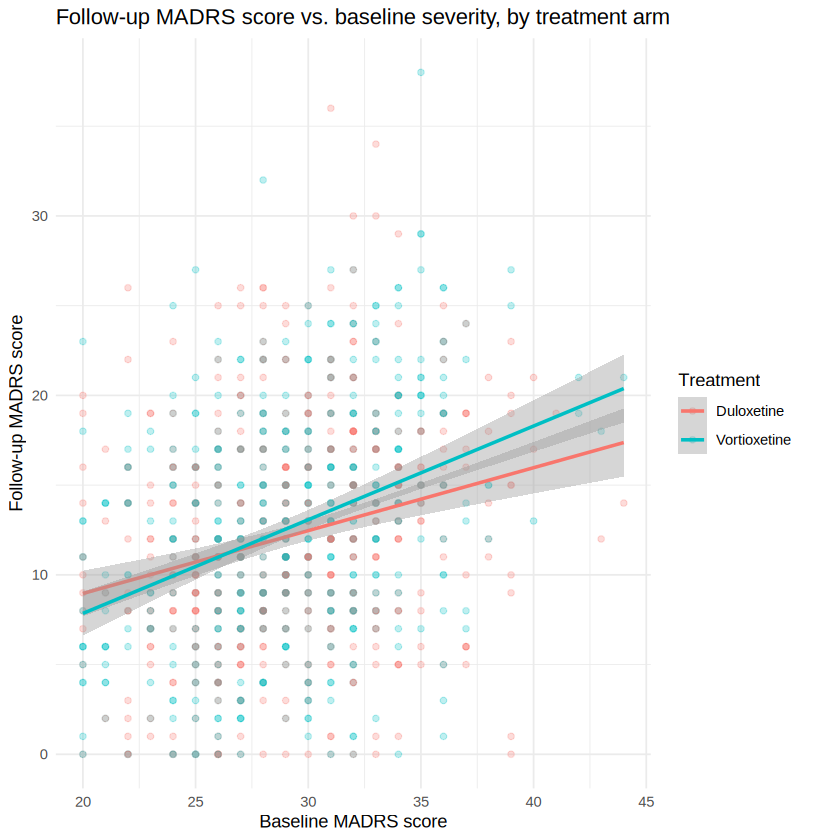

In [ ]:
ggplot(dat, aes(x = madrs_baseline, y = madrs_followup, color = treatment)) +
  geom_point(alpha = 0.25) +
  geom_smooth(method = "lm", se = TRUE) +
  labs(title = "Follow-up MADRS score vs. baseline severity, by treatment arm",
       x = "Baseline MADRS score", y = "Follow-up MADRS score", color = "Treatment") +
  theme_minimal()



We see the second plot trends upward -- patients who are more severe at
baseline, tend to have somewhat higher (worse) follow-up scores overall. What we're actually looking for isn't a flat line;
it's whether the **gap between the two colored lines** changes across the
x-axis. If the two lines stay a constant distance apart, that covariate
isn't much of a moderator; if the gap widens, narrows, or crosses, that's
a hint of heterogeneity.

For comparison, here's a covariate we *don't* expect to be a moderator --
smoking status. Note that smoking status is a binary variable, so instead of looking at a scatterplot, the analogous question becomes: is the vertical gap between the two treatment boxes the same size within non-smokers as it is within smokers?



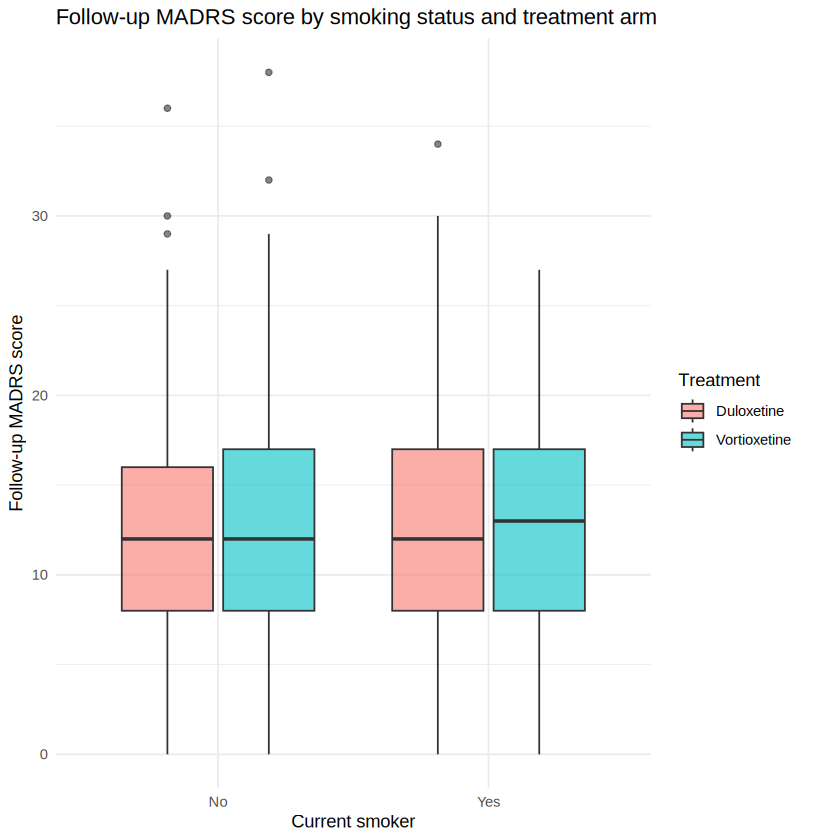

In [ ]:
ggplot(dat, aes(x = smoker, y = madrs_followup, fill = treatment)) +
  geom_boxplot(alpha = 0.6) +
  labs(title = "Follow-up MADRS score by smoking status and treatment arm",
       x = "Current smoker", y = "Follow-up MADRS score", fill = "Treatment") +
  theme_minimal()


It's hard to tell from this plot whether smoking status moderates the treatment effect. Within non-smokers, the two arms' medians sit almost on top of each other; within smokers, Vortioxetine's median looks a touch higher than Duloxetine's. But is that a real difference in how the treatments compare, or just how this particular sample of smokers happened to land? In the following sections we'll be able to test / model this explicitly.

**Discussion:** Based on these plots, `age` and `madrs_baseline` look like
promising candidate effect moderators -- the gap between the treatment
lines changes noticeably across their range. `smoker` looks more ambiguous -- worth keeping in the dataset, but not an obvious driver of
*who* benefits more. We'll carry `age` and `madrs_baseline` forward into
Segment 4. (We haven't looked at `weight_kg` yet -- that's one of the
covariates you can explore below.)

### Your turn: explore a covariate of your choice

Before we move on, pick a covariate we haven't plotted yet -- `weight_kg`
or `sex` are good candidates -- and decide for yourself whether it looks
like an effect moderator. Copy the chunk below, replace `COVARIATE_NAME`
with a column name from `dat`, and run it. If your covariate is
categorical (like `sex`) swap `geom_point()` + `geom_smooth()` for
`geom_boxplot()` as in the smoking example above.



In [ ]:
# YOUR TURN -- replace COVARIATE_NAME (no quotes) with a column from dat,
# then run this chunk yourself (select the code and press Cmd/Ctrl+Enter,
# or change eval=FALSE to eval=TRUE above).
ggplot(dat, aes(x = COVARIATE_NAME, y = madrs_followup, color = treatment)) +
  geom_point(alpha = 0.25) +
  geom_smooth(method = "lm", se = TRUE) +
  theme_minimal()



**Discussion questions:**

- Does Table 1 suggest randomization balanced the two arms well? What
  would it mean for our later analyses if it hadn't?
- Looking at the histogram in 3.3.1 and the response/remission rates in
  3.5, does the *overall* level of improvement in this trial look
  clinically meaningful, using the benchmarks in 3.3.2? Does that change
  once you consider the two arms separately, or specific subgroups?
- From the plots in 3.6, which covariates look like candidate moderators,
  and which look like noise? How confident are you eyeballing this from a
  picture alone -- what could go wrong with that approach (e.g., how many
  plots did we look at, and does that matter)?
- We often distinguish **pre-specified subgroups** (chosen in
  advance, based on clinical reasoning) from **exploratory** checks (like
  scanning plots for anything that looks different). Which are we doing in
  Segment 3? What are the risks of exploratory subgroup-hunting if you
  don't follow it up carefully (hint: multiple comparisons)?

---

# Segment 4: Traditional approaches, single study

**Goal:** formally test whether `age` and `madrs_baseline` modify the
treatment effect, using two classic tools: (a) a regression interaction
term, and (b) a stratified (subgroup) analysis.

## 4.1 Regression with a treatment x covariate interaction

The idea: fit a linear regression for the outcome that includes not just
`treatment` and the covariate on their own, but also their **product**
(the interaction term). The coefficient on that interaction term tells us
how much the treatment effect changes per one-unit increase in the
covariate.



In [ ]:
fit_age <- lm(madrs_followup ~ treatment * age + sex + smoker + weight_kg + madrs_baseline,
              data = dat)
summary(fit_age)



Call:
lm(formula = madrs_followup ~ treatment * age + sex + smoker + 
    weight_kg + madrs_baseline, data = dat)

Residuals:
     Min       1Q   Median       3Q      Max 
-16.6416  -4.2576  -0.2895   4.0574  23.0420 

Coefficients:
                            Estimate Std. Error t value Pr(>|t|)    
(Intercept)                2.4058466  1.9805669   1.215  0.22476    
treatmentVortioxetine     -3.4084807  1.4761080  -2.309  0.02114 *  
age                       -0.0610234  0.0222317  -2.745  0.00616 ** 
sexMale                    0.0175421  0.4724410   0.037  0.97039    
smokerYes                 -0.0575193  0.5012389  -0.115  0.90866    
weight_kg                  0.0002114  0.0120974   0.017  0.98606    
madrs_baseline             0.4298887  0.0444032   9.681  < 2e-16 ***
treatmentVortioxetine:age  0.0856426  0.0316980   2.702  0.00701 ** 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 6.179 on 992 degrees of freedom
Multiple R-squared: 


**How to read this output:** look for the row
`treatmentVortioxetine:age`. Its estimate tells you how much the
Vortioxetine-vs-Duloxetine treatment effect changes for every additional
year of age. A small p-value (< 0.05) on that row is evidence that age truly
modifies the treatment effect (i.e., that it's an effect moderator).
(Reminder from 3.3.3: lower score is better, so a negative coefficient here
would mean the vortioxetine-duloxetine gap shifts in vortioxetine's favor
as age increases, and a positive coefficient means it shifts in
duloxetine's favor.)

Now the same idea for baseline MADRS severity:



In [ ]:
fit_madrs <- lm(madrs_followup ~ treatment * madrs_baseline + age + sex + smoker + weight_kg,
                data = dat)
summary(fit_madrs)



Call:
lm(formula = madrs_followup ~ treatment * madrs_baseline + age + 
    sex + smoker + weight_kg, data = dat)

Residuals:
     Min       1Q   Median       3Q      Max 
-15.7141  -4.2402  -0.3368   4.1178  23.1538 

Coefficients:
                                      Estimate Std. Error t value Pr(>|t|)    
(Intercept)                           2.847566   2.229609   1.277   0.2018    
treatmentVortioxetine                -4.751502   2.612732  -1.819   0.0693 .  
madrs_baseline                        0.347824   0.062405   5.574 3.21e-08 ***
age                                  -0.020614   0.015962  -1.291   0.1969    
sexMale                               0.056657   0.473379   0.120   0.9048    
smokerYes                            -0.041241   0.501991  -0.082   0.9345    
weight_kg                             0.001502   0.012117   0.124   0.9014    
treatmentVortioxetine:madrs_baseline  0.177740   0.088503   2.008   0.0449 *  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.


Look for the `treatmentVortioxetine:madrs_baseline` row this time.

You can also put both interactions in the same model if you want to see
whether age and baseline severity each modify the effect *after
accounting for* the other:



In [ ]:
fit_both <- lm(madrs_followup ~ treatment * age + treatment * madrs_baseline +
                 sex + smoker + weight_kg,
               data = dat)
summary(fit_both)



Call:
lm(formula = madrs_followup ~ treatment * age + treatment * madrs_baseline + 
    sex + smoker + weight_kg, data = dat)

Residuals:
     Min       1Q   Median       3Q      Max 
-15.8030  -4.1979  -0.2791   4.0275  23.1773 

Coefficients:
                                       Estimate Std. Error t value Pr(>|t|)    
(Intercept)                           5.0429579  2.3643862   2.133  0.03318 *  
treatmentVortioxetine                -8.6678283  2.9756301  -2.913  0.00366 ** 
age                                  -0.0627905  0.0222136  -2.827  0.00480 ** 
madrs_baseline                        0.3409633  0.0622558   5.477 5.49e-08 ***
sexMale                               0.0444013  0.4718799   0.094  0.92505    
smokerYes                            -0.0673487  0.5004710  -0.135  0.89298    
weight_kg                             0.0007506  0.0120812   0.062  0.95047    
treatmentVortioxetine:age             0.0861120  0.0316488   2.721  0.00663 ** 
treatmentVortioxetine:madrs_baseli


## 4.2 Stratified analysis

A more intuitive (if less statistically efficient) alternative: split
patients into groups based on a covariate, and simply estimate the
treatment effect *separately within each group*. As below, we compute each
stratum's effect as Vortioxetine's mean follow-up score minus Duloxetine's
mean follow-up score -- so, same reminder as always, **negative =
vortioxetine better (lower score), positive = duloxetine better.**

### By age group





Table: Estimated treatment effect (Vortioxetine - Duloxetine) by age group

|age_group | effect| lower| upper|
|:---------|------:|-----:|-----:|
|Under 35  |  -0.82| -2.43|  0.79|
|35-55     |   0.00| -1.06|  1.06|
|Over 55   |   2.66|  0.83|  4.49|

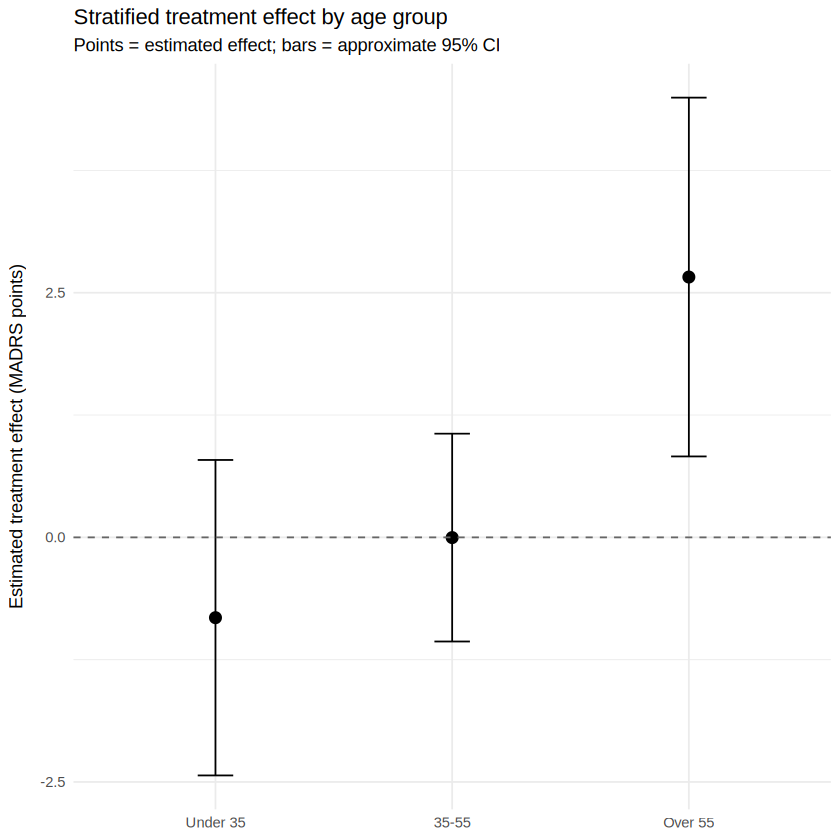

In [ ]:
dat <- dat %>%
  mutate(age_group = cut(age,
                          breaks = c(-Inf, 35, 55, Inf),
                          labels = c("Under 35", "35-55", "Over 55")))

age_strata <- dat %>%
  group_by(age_group, treatment) %>%
  summarise(mean_followup = mean(madrs_followup),
            se = sd(madrs_followup) / sqrt(n()),
            n = n(),
            .groups = "drop")

# Turn "mean follow-up score per arm" into "estimated treatment effect per
# stratum" (Vortioxetine mean minus Duloxetine mean), with an approximate
# 95% CI
age_effects <- age_strata %>%
  select(age_group, treatment, mean_followup, se) %>%
  pivot_wider(names_from = treatment, values_from = c(mean_followup, se)) %>%
  mutate(
    effect = mean_followup_Vortioxetine - mean_followup_Duloxetine,
    effect_se = sqrt(se_Vortioxetine^2 + se_Duloxetine^2),
    lower = effect - 1.96 * effect_se,
    upper = effect + 1.96 * effect_se
  )

kable(age_effects %>% select(age_group, effect, lower, upper),
      digits = 2,
      caption = "Estimated treatment effect (Vortioxetine - Duloxetine) by age group")

ggplot(age_effects, aes(x = age_group, y = effect)) +
  geom_point(size = 3) +
  geom_errorbar(aes(ymin = lower, ymax = upper), width = 0.15) +
  geom_hline(yintercept = 0, linetype = "dashed", color = "gray40") +
  labs(title = "Stratified treatment effect by age group",
       subtitle = "Points = estimated effect; bars = approximate 95% CI",
       x = NULL, y = "Estimated treatment effect (MADRS points)") +
  theme_minimal()


Splitting the sample by age gives a treatment effect that moves from negative to positive as age increases: under 35, the estimated effect is −0.82 points (95% CI −2.43 to 0.79), favoring Vortioxetine on average, though the interval crosses zero. In the 35–55 group, the effect is essentially 0.00 (−1.06 to 1.06) — no detectable difference between arms at all. Over 55, the effect climbs to +2.66 (0.83 to 4.49), favoring Duloxetine, and here the interval no longer contains zero. Read together, these three estimates trace out exactly the kind of pattern we're looking for in this session: the treatment comparison isn't one fixed number, it shifts systematically with age, from a slight edge for Vortioxetine in younger patients to a clearer, statistically supported edge for Duloxetine in patients over 55.


### By baseline severity group





Table: Estimated treatment effect (Vortioxetine - Duloxetine) by baseline severity group

|severity_group   | effect| lower| upper|
|:----------------|------:|-----:|-----:|
|Moderate (20-34) |   0.09| -0.75|  0.92|
|Severe (35+)     |   3.29|  0.83|  5.76|

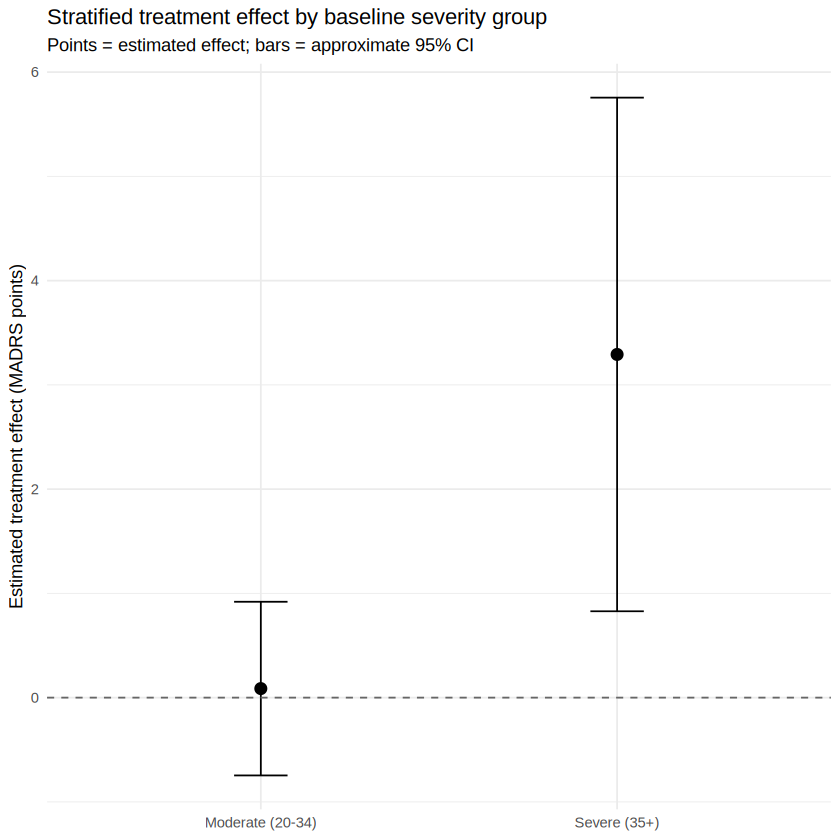

In [ ]:
dat <- dat %>%
  mutate(severity_group = cut(madrs_baseline,
                               breaks = c(-Inf, 34, Inf),
                               labels = c("Moderate (20-34)",
                                          "Severe (35+)")))
# These cutoffs use the guideline-based severity bands from 3.3.2, rather
# than an arbitrary median split.

sev_strata <- dat %>%
  group_by(severity_group, treatment) %>%
  summarise(mean_followup = mean(madrs_followup),
            se = sd(madrs_followup) / sqrt(n()),
            n = n(),
            .groups = "drop")

sev_effects <- sev_strata %>%
  select(severity_group, treatment, mean_followup, se) %>%
  pivot_wider(names_from = treatment, values_from = c(mean_followup, se)) %>%
  mutate(
    effect = mean_followup_Vortioxetine - mean_followup_Duloxetine,
    effect_se = sqrt(se_Vortioxetine^2 + se_Duloxetine^2),
    lower = effect - 1.96 * effect_se,
    upper = effect + 1.96 * effect_se
  )

kable(sev_effects %>% select(severity_group, effect, lower, upper),
      digits = 2,
      caption = "Estimated treatment effect (Vortioxetine - Duloxetine) by baseline severity group")

ggplot(sev_effects, aes(x = severity_group, y = effect)) +
  geom_point(size = 3) +
  geom_errorbar(aes(ymin = lower, ymax = upper), width = 0.15) +
  geom_hline(yintercept = 0, linetype = "dashed", color = "gray40") +
  labs(title = "Stratified treatment effect by baseline severity group",
       subtitle = "Points = estimated effect; bars = approximate 95% CI",
       x = NULL, y = "Estimated treatment effect (MADRS points)") +
  theme_minimal()


Splitting by baseline severity tells a similar story with two groups instead of three. Among moderate baseline MADRS (20–34), the estimated effect is 0.09 (−0.75 to 0.92) — negligible, with a tight interval around zero, meaning there's little to no difference for this group. Among severe baseline MADRS (35+), the effect jumps to 3.29 (0.83 to 5.76), favoring Duloxetine, with an interval that excludes zero but is noticeably wider — reflecting that this is a smaller subgroup, so we're less certain of the exact size of the effect even though we're confident it's not zero. Together, this suggests baseline severity, like age, is moderating which drug looks better — with the more severely depressed patients doing relatively better on Duloxetine, while moderate-severity patients show no clear preference either way.

**Discussion:**

- Do the interaction models and the stratified analyses tell a consistent
  story?
- What are the trade-offs? (Hint: stratifying throws away information --
  it treats "just under" and "just over" a cutoff as completely different
  groups, and cutting the sample into pieces costs precision. The
  interaction model uses all the data at once, but assumes the
  relationship between the covariate and the treatment effect is
  linear/log-linear -- is that believable here?)
- Both approaches require you to **pre-specify** which covariates to
  investigate. What if the true moderator was some combination of
  covariates you didn't think to try? That's exactly the motivation for
  Segment 5.

---

# Segment 5: Causal forest

**Goal:** fit a causal forest -- a machine-learning method that searches
*automatically* across covariates (and their combinations) for treatment
effect heterogeneity, rather than requiring us to specify it in advance.
We'll fit it on the exact same dataset so we can directly compare what it
finds to Segment 4.

## 5.0 What is a causal forest?

A **causal forest** (implemented in the `grf` -- "generalized random
forests" -- package) is a machine-learning method purpose-built for
estimating $\text{CATE}(x)$. In plain language:

- It builds a large number of individual **decision trees** (thousands).
  Each tree repeatedly splits patients into smaller and smaller groups
  based on their covariates, trying to find splits where the estimated
  treatment effect differs the most between the two resulting groups
  (rather than trying to predict the outcome directly, like a regular
  regression tree would).
- Each tree only sees a random subset of the data, and uses an **"honest"**
  splitting rule: one part of its subset decides *where* to split, and a
  separate part is used to *estimate* the treatment effect within each
  resulting group. This sample-splitting is what allows `grf` to produce
  statistically valid confidence intervals, not just point estimates.
- The **forest** then averages the predictions across all of these trees
  for a given patient's covariates, which smooths out the noise any one
  tree would have and gives a stable, flexible estimate of
  $\text{CATE}(x)$ for every patient.

The big advantage over Segment 4: we don't have to decide in advance
*which* covariates matter or *what shape* (linear? threshold? interaction
of several covariates?) the relationship should take -- the forest
searches over all of that automatically. The trade-off, as we'll see, is
that the result is a lot less transparent than a single regression
coefficient.

## 5.1 Fit the causal forest

`causal_forest()` (from the `grf` package) needs three ingredients:

- `X` -- a numeric matrix of covariates
- `Y` -- the outcome (numeric vector)
- `W` -- the treatment indicator (0 = control/Duloxetine,
  1 = treatment/Vortioxetine)



In [ ]:
# Build a numeric covariate matrix. causal_forest() needs everything as
# numbers, so we turn the two categorical covariates into 0/1 indicators.
X <- dat %>%
  transmute(
    age             = age,
    female          = as.numeric(sex == "Female"),
    current_smoker  = as.numeric(smoker == "Yes"),
    weight_kg       = weight_kg,
    madrs_baseline  = madrs_baseline
  ) %>%
  as.matrix()

W <- as.numeric(dat$treatment == "Vortioxetine")   # 1 = Vortioxetine, 0 = Duloxetine
Y <- dat$madrs_followup

set.seed(2026)
cf <- causal_forest(X, Y, W, num.trees = 2000)
cf


GRF forest object of type causal_forest 
Number of trees: 2000 
Number of training samples: 1000 
Variable importance: 
    1     2     3     4     5 
0.429 0.040 0.022 0.283 0.227 


## 5.2 Get patient-level CATE estimates

Once the forest is fit, we can ask it for an estimated
treatment effect for every patient in the data (their estimated CATE,
given their own covariate values). Same sign convention as always:
**negative `tau_hat` = vortioxetine estimated to help more; positive =
duloxetine estimated to help more.**



   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
-1.8540 -0.3973  0.1378  0.4011  1.1195  3.7676 

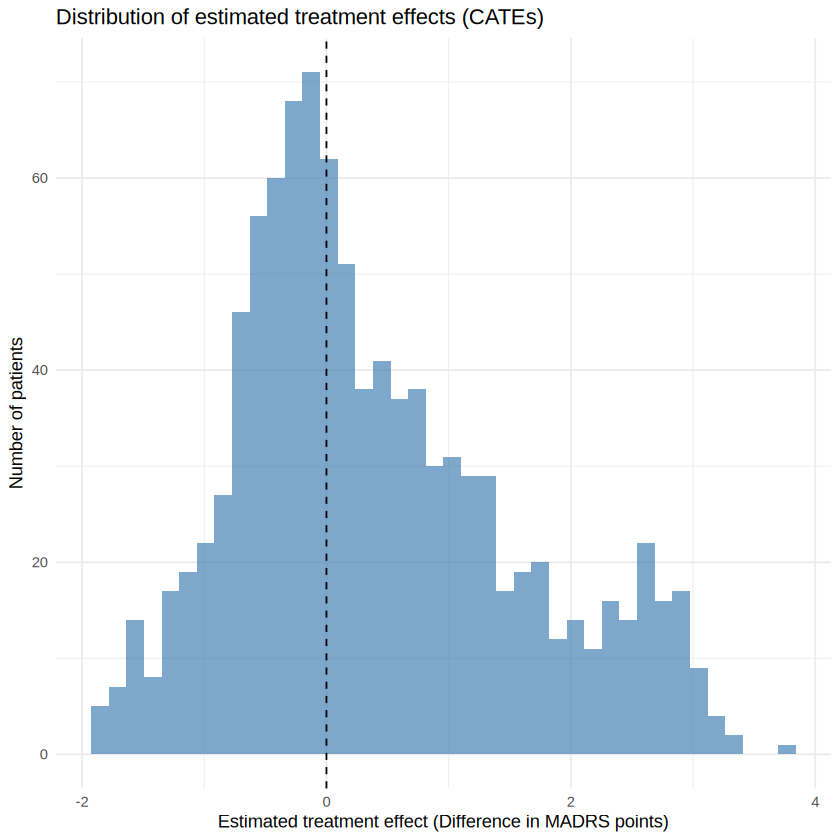

In [ ]:
dat$tau_hat <- predict(cf)$predictions

summary(dat$tau_hat)

ggplot(dat, aes(x = tau_hat)) +
  geom_histogram(bins = 40, fill = "steelblue", alpha = 0.7) +
  geom_vline(xintercept = 0, linetype = "dashed") +
  labs(title = "Distribution of estimated treatment effects (CATEs)",
       x = "Estimated treatment effect (Difference in MADRS points)", y = "Number of patients") +
  theme_minimal()



If every patient had (roughly) the same treatment effect, this histogram
would be a narrow spike. A wide spread is more evidence of heterogeneity.

## 5.3 Variable importance

Which covariates did the forest rely on most heavily when deciding how to
split patients into groups with different estimated effects?





Table: Causal forest variable importance

|covariate      | importance|
|:--------------|----------:|
|age            |      0.429|
|weight_kg      |      0.283|
|madrs_baseline |      0.227|
|female         |      0.040|
|current_smoker |      0.022|

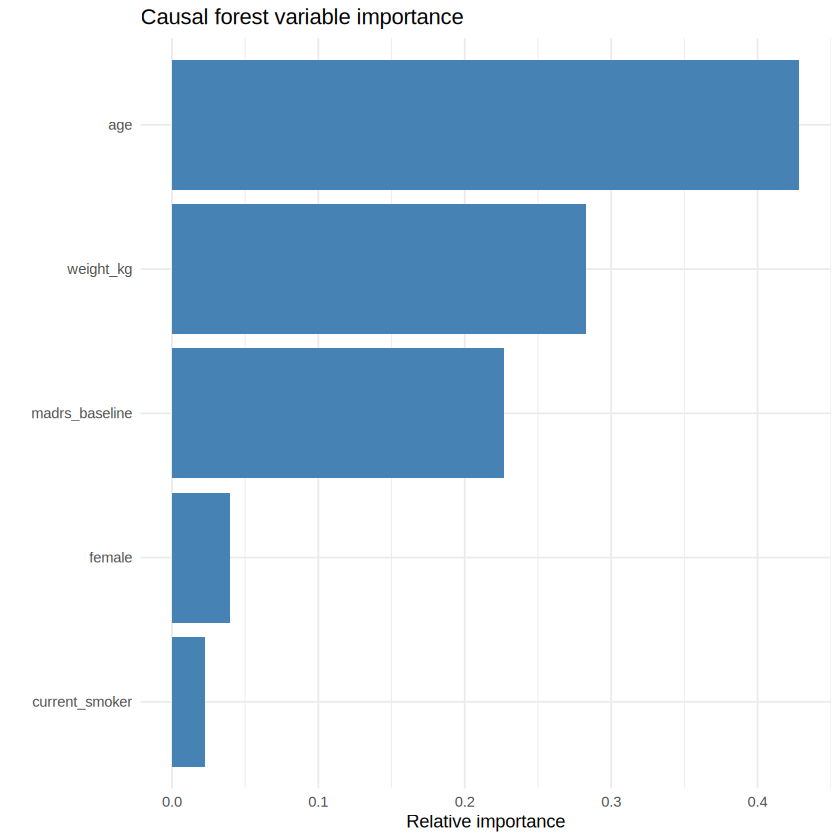

In [ ]:
varimp <- variable_importance(cf)
varimp_df <- data.frame(covariate = colnames(X), importance = as.numeric(varimp)) %>%
  arrange(desc(importance))

kable(varimp_df, digits = 3, caption = "Causal forest variable importance")

ggplot(varimp_df, aes(x = reorder(covariate, importance), y = importance)) +
  geom_col(fill = "steelblue") +
  coord_flip() +
  labs(title = "Causal forest variable importance",
       x = NULL, y = "Relative importance") +
  theme_minimal()



Compare this to what we guessed from the pictures in Segment 3, and what
the interaction models in Segment 4 found. Does the forest agree that age
and baseline severity matter most?

*A caveat worth knowing:* this importance measure can be inflated for
continuous covariates with many possible split points (like `weight_kg`
here), even when they aren't true effect moderators -- a known limitation
of variable importance metrics that are based on how often the variable is used in splits in the trees. That's one reason we don't rely on
variable importance alone, and instead also look at the interpretation
tree, the CATE-vs-covariate plots, and (in the stretch material) a formal
calibration test and best linear projection.

## 5.4 An "interpretation tree" for the forest

A causal forest is really a large collection (e.g. 2000) of individual
trees averaged together -- which makes it very flexible, but hard to
summarize in one picture. A simple trick: fit *one small, shallow* regular
decision tree that predicts the forest's own CATE estimates
(`tau_hat`) from the covariates. This won't be as accurate as the full
forest, but it gives us an easy-to-read summary of the forest's main
splits.



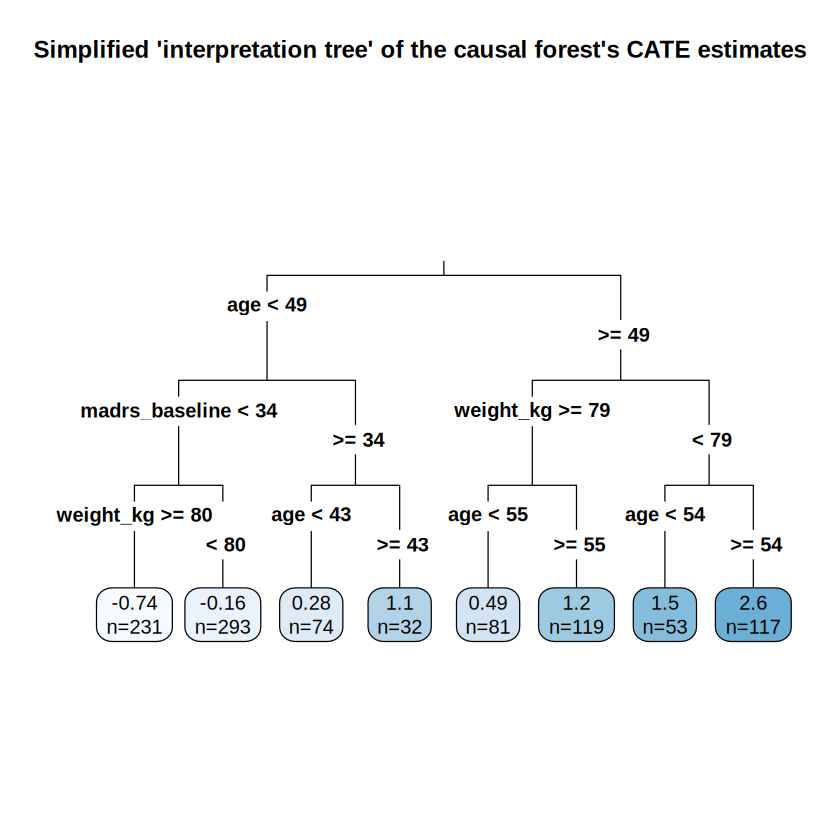

In [ ]:
tree_data <- dat %>%
  select(tau_hat, age, sex, smoker, weight_kg, madrs_baseline)

interpretation_tree <- rpart(tau_hat ~ age + sex + smoker + weight_kg + madrs_baseline,
                              data = tree_data,
                              maxdepth = 3, cp = 0.01)

rpart.plot(interpretation_tree, type = 3, extra = 1, digits = 2,
           main = "Simplified 'interpretation tree' of the causal forest's CATE estimates")



Each box shows the average predicted treatment effect for patients in that
group, and the split rules show which covariates the tree used to divide
patients up. This is a nice plain-language summary to bring back to a
clinical audience, even though it's a simplification of what the full
forest is actually doing.

## 5.5 CATE vs. a covariate

Just like we did with the raw data in Segment 3, we can plot the forest's
*estimated* treatment effect against a covariate to see the shape of the
heterogeneity it found:



`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


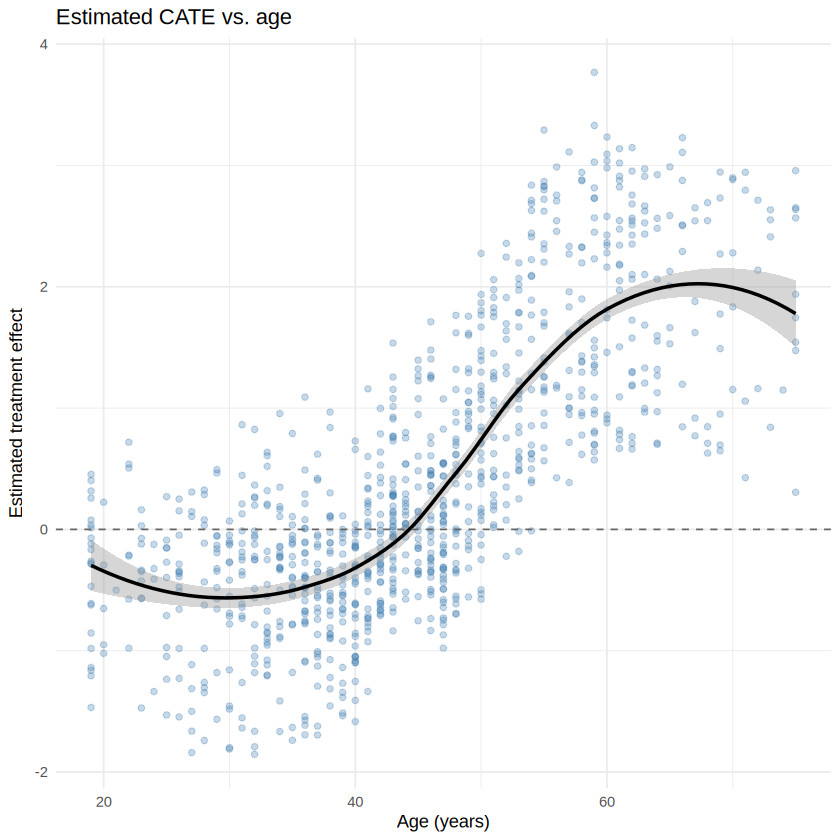

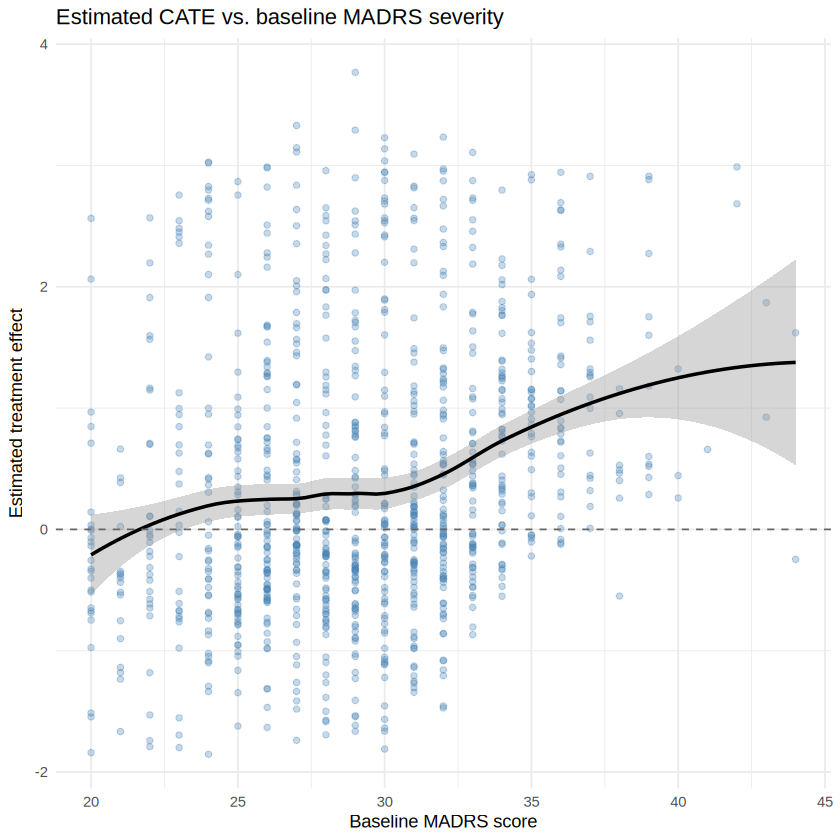

In [ ]:
ggplot(dat, aes(x = age, y = tau_hat)) +
  geom_point(alpha = 0.3, color = "steelblue") +
  geom_smooth(method = "loess", color = "black") +
  geom_hline(yintercept = 0, linetype = "dashed", color = "gray40") +
  labs(title = "Estimated CATE vs. age",
       x = "Age (years)", y = "Estimated treatment effect") +
  theme_minimal()

ggplot(dat, aes(x = madrs_baseline, y = tau_hat)) +
  geom_point(alpha = 0.3, color = "steelblue") +
  geom_smooth(method = "loess", color = "black") +
  geom_hline(yintercept = 0, linetype = "dashed", color = "gray40") +
  labs(title = "Estimated CATE vs. baseline MADRS severity",
       x = "Baseline MADRS score", y = "Estimated treatment effect") +
  theme_minimal()



**Discussion:** how does this compare to the interaction-model and
stratified-analysis results from Segment 4? This is the flexibility vs.
interpretability trade-off in action: the forest didn't need us to specify
*which* covariates mattered or *what shape* the relationship should take
-- but its output (2000 averaged trees) is inherently harder to write down
in a single sentence or equation than a regression coefficient.

### Your turn: pick a covariate for the CATE plot

Try the same kind of plot for a covariate we haven't checked yet (e.g.
`sex` or `smoker` -- you'll want `geom_boxplot()` instead of
`geom_point()`/`geom_smooth()` for those, as in Segment 3.6).



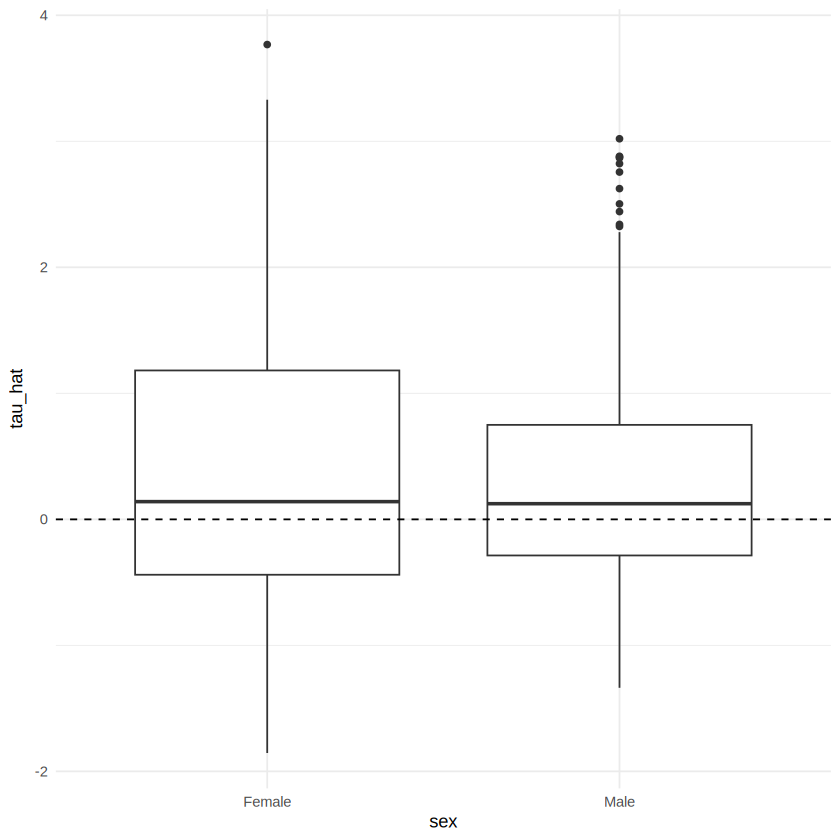

In [ ]:
# YOUR TURN -- replace COVARIATE_NAME with a column from dat, then run
# this chunk yourself.
ggplot(dat, aes(x = COVARIATE_NAME, y = tau_hat)) +
  geom_point(alpha = 0.3, color = "steelblue") +
  geom_smooth(method = "loess", color = "black") +
  geom_hline(yintercept = 0, linetype = "dashed") +
  theme_minimal()



---

## STRETCH MATERIAL

*The rest of this notebook is optional "if we have time" material. Feel
free to run it now, or come back to it later on your own -- the code is
fully commented either way.*

### 5.6 (Stretch) Is there statistically significant heterogeneity at all?

`test_calibration()` runs a formal omnibus test of whether the forest
found *any* meaningful heterogeneity (as opposed to just noise). Very
loosely: `differential.forest.prediction` measures whether patients with
higher vs. lower predicted CATEs really do have different observed
outcomes; a p-value near 0 is evidence of true, detectable heterogeneity.



In [ ]:
test_calibration(cf)



Best linear fit using forest predictions (on held-out data)
as well as the mean forest prediction as regressors, along
with one-sided heteroskedasticity-robust (HC3) SEs:

                               Estimate Std. Error t value  Pr(>t)  
mean.forest.prediction          0.94513    0.98556  0.9590 0.16890  
differential.forest.prediction  0.72279    0.34101  2.1196 0.01714 *
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



### 5.7 (Stretch) Best linear projection

If you want an interaction-model-style, single-number summary out of the
forest (instead of just a picture), `best_linear_projection()` projects
the forest's fine-grained CATE estimates onto a simple linear function of
whichever covariates you choose. It's a nice bridge back to the Segment 4
regression output -- same style of coefficient table, but built from what
the forest learned rather than an interaction term we had to specify by
hand.



In [ ]:
best_linear_projection(cf, X[, c("age", "madrs_baseline")])



Best linear projection of the conditional average treatment effect.
Confidence intervals are cluster- and heteroskedasticity-robust (HC3):

                Estimate Std. Error t value Pr(>|t|)   
(Intercept)    -8.442603   2.986790 -2.8266 0.004798 **
age             0.096767   0.032355  2.9908 0.002851 **
madrs_baseline  0.152938   0.090033  1.6987 0.089690 . 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


### 5.8 (Stretch) Exploring uncertainty

Every `tau_hat` we've looked at so far is a point estimate -- our single
best guess at that patient profile's treatment effect. But just like a
regression coefficient comes with a standard error, so does each forest
CATE estimate.

In [ ]:
# estimate.variance = TRUE asks the forest for a standard error alongside
# each patient's point estimate, using the same honest trees we already
# grew in 5.1 -- no need to re-fit cf itself.
cf_pred <- predict(cf, estimate.variance = TRUE)

dat$tau_hat   <- cf_pred$predictions
dat$tau_se    <- sqrt(cf_pred$variance.estimates)
dat$tau_lower <- dat$tau_hat - 1.96 * dat$tau_se
dat$tau_upper <- dat$tau_hat + 1.96 * dat$tau_se

summary(dat$tau_se)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.3502  0.7788  0.9516  0.9459  1.1084  1.6280 

Now let's plot every patient's estimated CATE with its 95% CI, sorted
from most-negative (Vortioxetine estimated to help most) to most-positive
(Duloxetine estimated to help most)

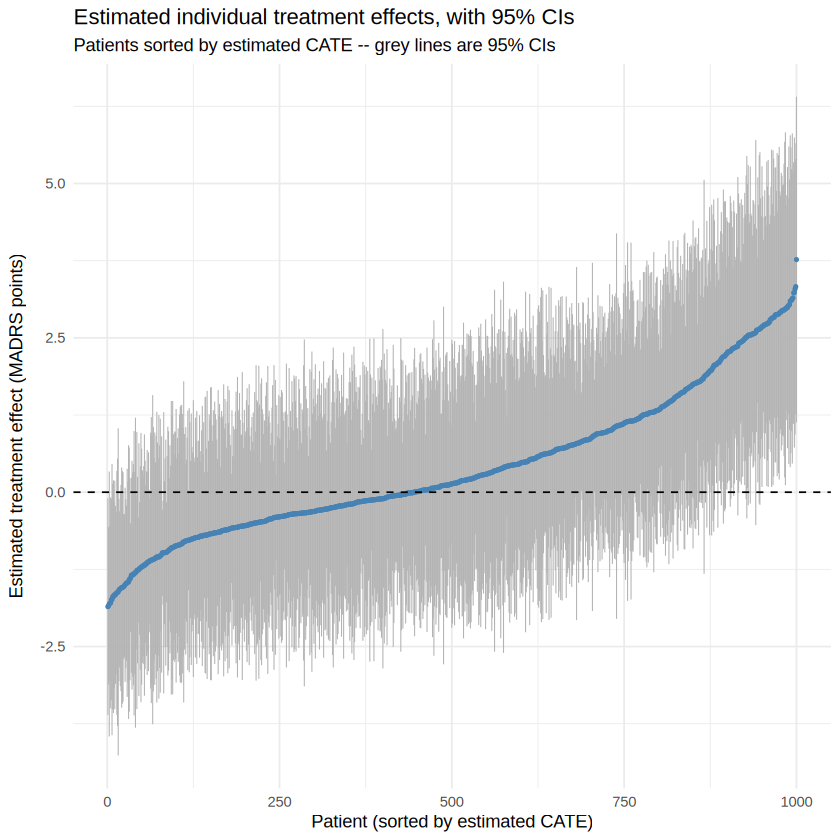

In [ ]:
dat_sorted <- dat %>%
  arrange(tau_hat) %>%
  mutate(rank = row_number())

ggplot(dat_sorted, aes(x = rank, y = tau_hat)) +
  geom_errorbar(aes(ymin = tau_lower, ymax = tau_upper),
                color = "grey70", width = 0, linewidth = 0.3) +
  geom_point(color = "steelblue", size = 0.8) +
  geom_hline(yintercept = 0, linetype = "dashed", color = "black") +
  labs(title = "Estimated individual treatment effects, with 95% CIs",
       subtitle = "Patients sorted by estimated CATE -- grey lines are 95% CIs",
       x = "Patient (sorted by estimated CATE)",
       y = "Estimated treatment effect (Difference in MADRS points)") +
  theme_minimal()

**Discussion:** Notice how wide most of these individual confidence
intervals are, and how many of them cross the dashed zero line -- in this
dataset, only about 15% of patients have a 95% CI that excludes zero
entirely. That doesn't mean the heterogeneity we've been finding all
session is fake: `test_calibration()` still finds real, systematic
differences in treatment effect across the group as a whole, and the
*pattern* (older/more-severe patients favoring Duloxetine) is a genuine
population-level signal. But it's an important caution for how far to
trust any *individual* number: `tau_hat` for one specific patient is a
noisy estimate, not a certainty, and we can be more confident in where heterogeneity tends to live than at pinning down any
one person's exact effect.


### 5.8 (Stretch, simulation-only bonus) Checking against the truth

Because this is simulated data, we actually know each patient's *true*
individual treatment effect (`true_cate` in the original .csv -- something
you would never have access to with real data!). Let's see how close the
forest's estimates came:



Correlation between estimated and true CATE: 0.69 


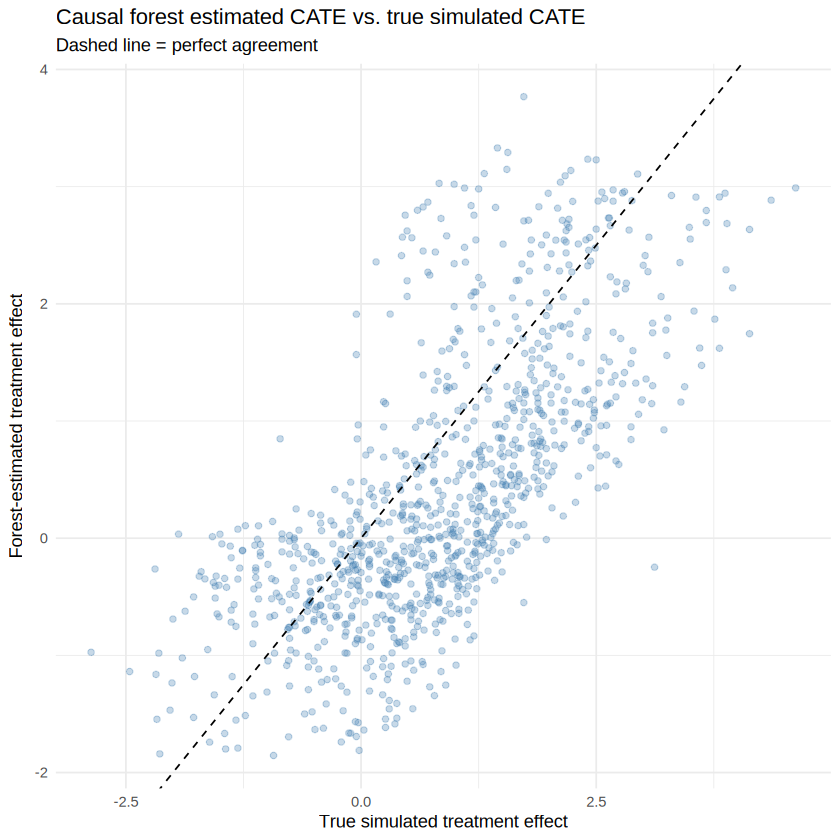

In [ ]:
truth_check <- read.csv(data_url) %>%
  select(patient_id, true_cate) %>%
  left_join(dat %>% select(patient_id, tau_hat), by = "patient_id")

cat("Correlation between estimated and true CATE:",
    round(cor(truth_check$tau_hat, truth_check$true_cate), 2), "\n")

ggplot(truth_check, aes(x = true_cate, y = tau_hat)) +
  geom_point(alpha = 0.3, color = "steelblue") +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed") +
  labs(title = "Causal forest estimated CATE vs. true simulated CATE",
       subtitle = "Dashed line = perfect agreement",
       x = "True simulated treatment effect", y = "Forest-estimated treatment effect") +
  theme_minimal()



---

*End of the coding portion. We'll pick back up with slides for Segment 6
(where to go deeper) and Segment 7 (Q&A).*
